In [1]:
from pathlib import Path
from datetime import datetime
import yaml
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np

In [2]:
# ============================================================
# パス設定（すべてここで完結）
# ============================================================

# --- 実データ ---
REAL_DATA_DIR   = Path("data/datasets/font2dataset_upper_google_64/images")
REAL_PARQUET    = Path("models/2026-06-15-11-30_scorer_H/checkpoints/step003150-auroc0.6284/score/font2dataset_upper_google_64_scores.parquet")
REAL_SPLIT_FILE = Path("config/split_ascii_seed42.yaml")

# --- 生成データ ---
GEN_DATA_DIR    = Path("results/2026-06-06-15-50_diffusion_uppercase/checkpoints/last-ema/images")
GEN_PARQUET     = Path("models/2026-06-15-11-30_scorer_H/checkpoints/step003150-auroc0.6284/score/last-ema_scores.parquet")
GEN_SPLIT_FILE  = Path("results/2026-06-06-15-50_diffusion_uppercase/checkpoints/last-ema/split_seed42.yaml")

# ============================================================
# 表示設定
# ============================================================
SPLIT           = "train"     # "train" / "val" / "test" / "all"
FILTER_CHARS    = list("H")  # 表示する文字（空リストで全文字）。real/gen 読み込み時点で適用し、以後の全セクションで厳守する
FILTER_FAMILY   = ""         # フォントファミリー名の部分一致フィルタ（空文字で全て）
MAX_PER_CHAR    = 20
COLS            = 10
IMG_SIZE        = 1.2
BINARIZE        = True      # True で画像を二値化して表示
BINARIZE_THRESHOLD = 0.5     # 二値化閾値（0–1）

# ============================================================
# 図の保存設定
# ============================================================
SAVE_FIGURES = True  # Trueの場合、図・統計データをOUTPUT_DIRに保存する
# OUTPUT_DIR = Path("outputs/analysis") / f"{datetime.now():%Y-%m-%d}_image_viewer3"
OUTPUT_DIR = Path("models/2026-06-15-11-30_scorer_H/checkpoints/step003150-auroc0.6284/viewer")
if SAVE_FIGURES:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def _save_fig(fig, name: str) -> None:
    """SAVE_FIGURES=Trueなら fig を OUTPUT_DIR/{name}.png に保存する。"""
    if SAVE_FIGURES:
        fig.savefig(OUTPUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def _save_df(df: pd.DataFrame, name: str) -> None:
    """SAVE_FIGURES=Trueなら df を OUTPUT_DIR/{name}.csv に保存する。"""
    if SAVE_FIGURES:
        df.to_csv(OUTPUT_DIR / f"{name}.csv")


def _save_config(config: dict, name: str = "config") -> None:
    """SAVE_FIGURES=Trueなら config を OUTPUT_DIR/{name}.yaml に保存する。"""
    if SAVE_FIGURES:
        serializable = {k: (str(v) if isinstance(v, Path) else v) for k, v in config.items()}
        with open(OUTPUT_DIR / f"{name}.yaml", "w") as f:
            yaml.dump(serializable, f, allow_unicode=True, sort_keys=False)

# ============================================================
# ユーティリティ
# ============================================================
def _load_image(path: Path) -> np.ndarray:
    img = mpimg.imread(str(path))
    if img.ndim == 3:
        img = img.mean(axis=2)          # グレースケール化
    img = img.astype(float)
    if img.max() > 1.0:
        img = img / 255.0
    if BINARIZE:
        img = (img >= BINARIZE_THRESHOLD).astype(float)
    return img


def _filter_chars(df: pd.DataFrame, chars: list[str]) -> pd.DataFrame:
    if chars and "char" in df.columns:
        return df[df["char"].isin(chars)]
    return df

# ============================================================
# データ読み込み・スプリットフィルタ
# ============================================================
def _load_split_families(split_file: Path, split: str) -> set[str] | None:
    if split_file is None or not split_file.exists() or split == "all":
        return None
    with open(split_file) as f:
        cfg = yaml.safe_load(f)
    return set(cfg["families"][split])

def _load_split_files(split_file: Path, split: str) -> set[str] | None:
    if split_file is None or not split_file.exists() or split == "all":
        return None
    with open(split_file) as f:
        cfg = yaml.safe_load(f)
    return set(cfg["files"][split])

real_families = _load_split_families(REAL_SPLIT_FILE, SPLIT)
gen_files     = _load_split_files(GEN_SPLIT_FILE, SPLIT)

real = pd.read_parquet(REAL_PARQUET)
if real_families is not None:
    real = real[real["font_family"].isin(real_families)]

gen = pd.read_parquet(GEN_PARQUET)
if gen_files is not None:
    gen = gen[gen["file"].isin(gen_files)]

real["_source"] = "real"
gen["_source"]  = "generated"

# FILTER_CHARS をここで適用し、以後の全セクションで厳守する
real = _filter_chars(real, FILTER_CHARS)
gen  = _filter_chars(gen,  FILTER_CHARS)

for name, df in [("Real", real), ("Generated", gen)]:
    s = df["realness_score"]
    print(f"{name}: n={len(df):,}  mean={s.mean():.4f}  std={s.std():.4f}  "
          f"min={s.min():.4f}  max={s.max():.4f}")

Real: n=2,656  mean=0.3934  std=0.0601  min=0.0942  max=0.6361
Generated: n=2,650  mean=0.2916  std=0.0574  min=0.1616  max=0.4820


## Realness Score 分布比較

/tmp/ipykernel_83030/57155768.py:27: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(


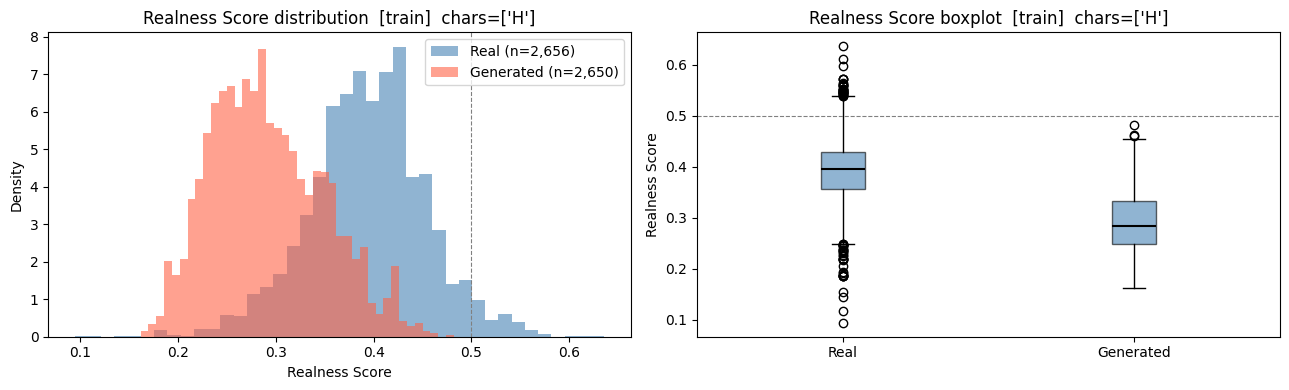

,Real,Generated
count,2656.0000,2650.0000
mean,0.3934,0.2916
std,0.0601,0.0574
min,0.0942,0.1616
25%,0.3573,0.2481
50%,0.3951,0.2847
75%,0.4295,0.3321
max,0.6361,0.4820


In [3]:
DISPLAY_MODE      = "score"    # "score" | "logit"

def _get_values(df: pd.DataFrame, mode: str) -> np.ndarray:
    s = df["realness_score"].values.astype(float)
    if mode == "logit":
        s = np.clip(s, 1e-6, 1 - 1e-6)
        return np.log(s / (1 - s))
    return s

rv_vals = _get_values(real, DISPLAY_MODE)
gv_vals = _get_values(gen, DISPLAY_MODE)
xlabel  = "Logit" if DISPLAY_MODE == "logit" else "Realness Score"
thresh  = 0.0 if DISPLAY_MODE == "logit" else 0.5

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for vals, color, label in [(rv_vals, "steelblue", "Real"), (gv_vals, "tomato", "Generated")]:
    axes[0].hist(vals, bins=40, alpha=0.6, color=color,
                 label=f"{label} (n={len(vals):,})", density=True)
axes[0].axvline(thresh, color="gray", linestyle="--", linewidth=0.8)
axes[0].set_xlabel(xlabel)
axes[0].set_ylabel("Density")
char_info = f"  chars={FILTER_CHARS}" if FILTER_CHARS else ""
axes[0].set_title(f"{xlabel} distribution  [{SPLIT}]{char_info}")
axes[0].legend()

axes[1].boxplot(
    [rv_vals, gv_vals],
    labels=["Real", "Generated"],
    patch_artist=True,
    medianprops=dict(color="black", linewidth=1.5),
    boxprops=dict(facecolor="steelblue", alpha=0.6),
)
axes[1].axhline(thresh, color="gray", linestyle="--", linewidth=0.8)
axes[1].set_ylabel(xlabel)
axes[1].set_title(f"{xlabel} boxplot  [{SPLIT}]{char_info}")

fig.tight_layout()
_save_fig(fig, "01_score_distribution")
plt.show()

summary = pd.DataFrame({
    "Real":      pd.Series(rv_vals).describe(),
    "Generated": pd.Series(gv_vals).describe(),
})
_save_df(summary, "01_score_distribution_summary")
display(summary.round(4))

## 画像グリッド表示（実 / 生成を並べて比較）

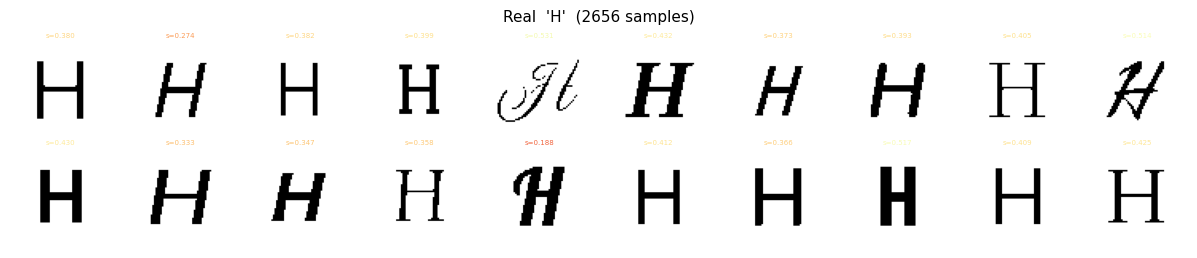

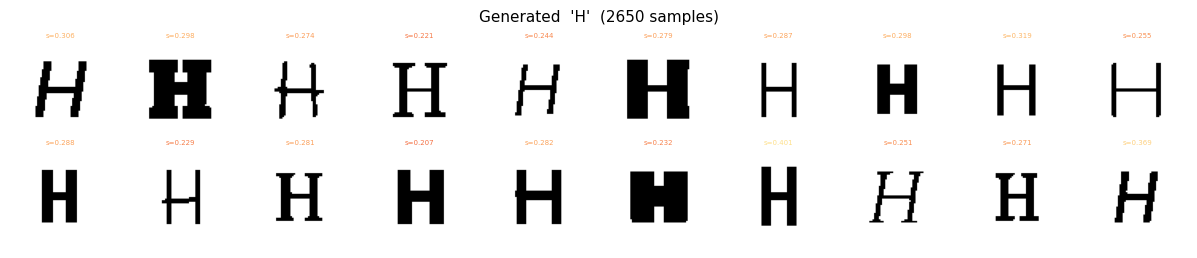

In [4]:
def show_grid(df: pd.DataFrame, images_dir: Path, title: str,
              max_images: int = 20, cols: int = 10, img_size: float = 1.2,
              save_name: str | None = None) -> None:
    has_score = "realness_score" in df.columns and df["realness_score"].notna().any()
    sample = df.sample(min(max_images, len(df)), random_state=0)
    n = len(sample)
    if n == 0:
        print(f"[{title}] 表示対象なし")
        return
    nrows = (n + cols - 1) // cols
    fig, axes = plt.subplots(nrows, cols, figsize=(cols * img_size, nrows * img_size))
    axes = np.array(axes).reshape(-1)
    for ax, (_, row) in zip(axes, sample.iterrows()):
        path = images_dir / row["file"]
        if path.exists():
            ax.imshow(_load_image(path), cmap="gray", vmin=0, vmax=1)
        else:
            ax.text(0.5, 0.5, "N/A", ha="center", va="center", fontsize=6)
        if has_score and pd.notna(row.get("realness_score")):
            score = float(row["realness_score"])
            ax.set_title(f"s={score:.3f}", fontsize=5, pad=1,
                         color=plt.cm.RdYlGn(score))
        else:
            label = str(row.get("font_family", ""))[:12]
            ax.set_title(label, fontsize=5, pad=1)
        ax.axis("off")
    for ax in axes[n:]:
        ax.axis("off")
    fig.suptitle(title, fontsize=11, y=1.01)
    fig.tight_layout(pad=0.3)
    if save_name:
        _save_fig(fig, save_name)
    plt.show()


rv = _filter_chars(real, FILTER_CHARS)
gv = _filter_chars(gen,  FILTER_CHARS)
if FILTER_FAMILY:
    if "font_family" in rv.columns:
        rv = rv[rv["font_family"].str.contains(FILTER_FAMILY, case=False, na=False)]

char_list = sorted(rv["char"].unique()) if "char" in rv.columns and not FILTER_CHARS else (FILTER_CHARS or [None])

for char in char_list:
    if char is not None:
        rv_c = rv[rv["char"] == char]
        gv_c = gv[gv["char"] == char] if "char" in gv.columns else gv
    else:
        rv_c, gv_c = rv, gv

    show_grid(rv_c, REAL_DATA_DIR,
              title=f"Real  '{char}'  ({len(rv_c)} samples)",
              max_images=MAX_PER_CHAR, cols=COLS, img_size=IMG_SIZE,
              save_name=f"02_image_grid_real_{char}")
    show_grid(gv_c, GEN_DATA_DIR,
              title=f"Generated  '{char}'  ({len(gv_c)} samples)",
              max_images=MAX_PER_CHAR, cols=COLS, img_size=IMG_SIZE,
              save_name=f"02_image_grid_gen_{char}")

## Score Top-N / Bottom-N（実 / 生成それぞれ）

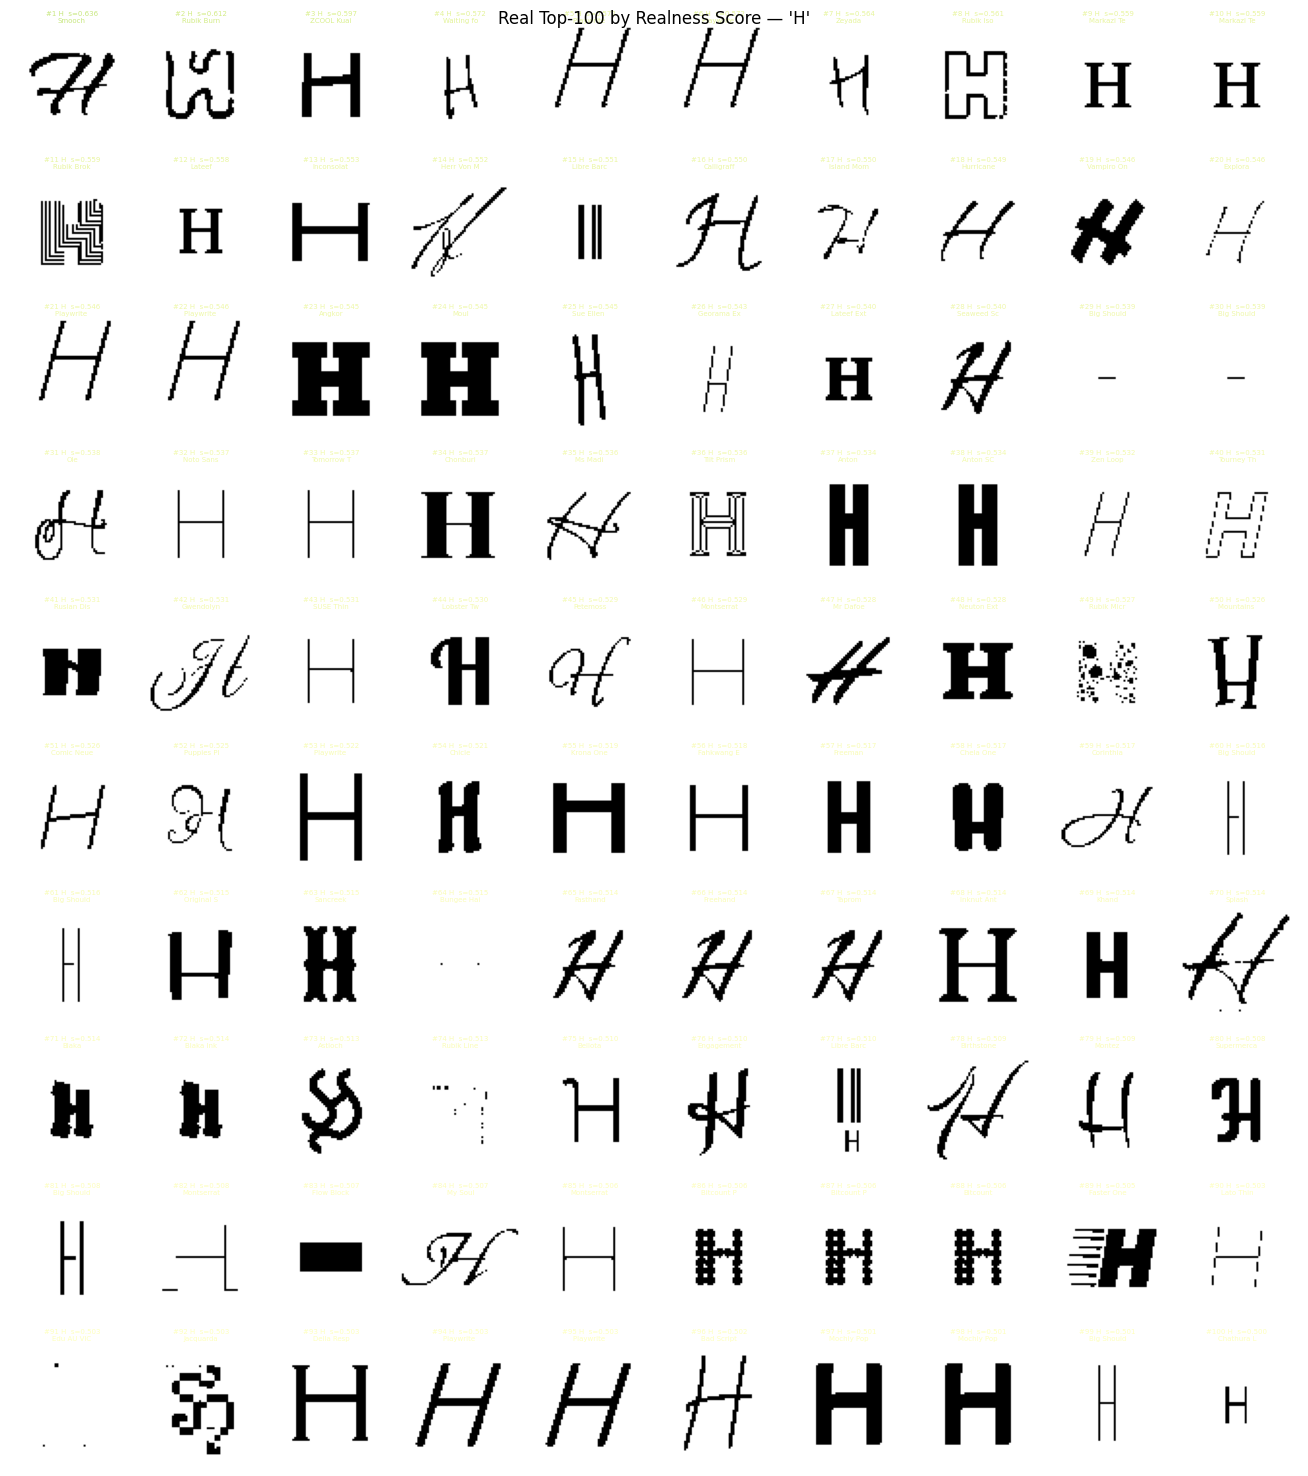

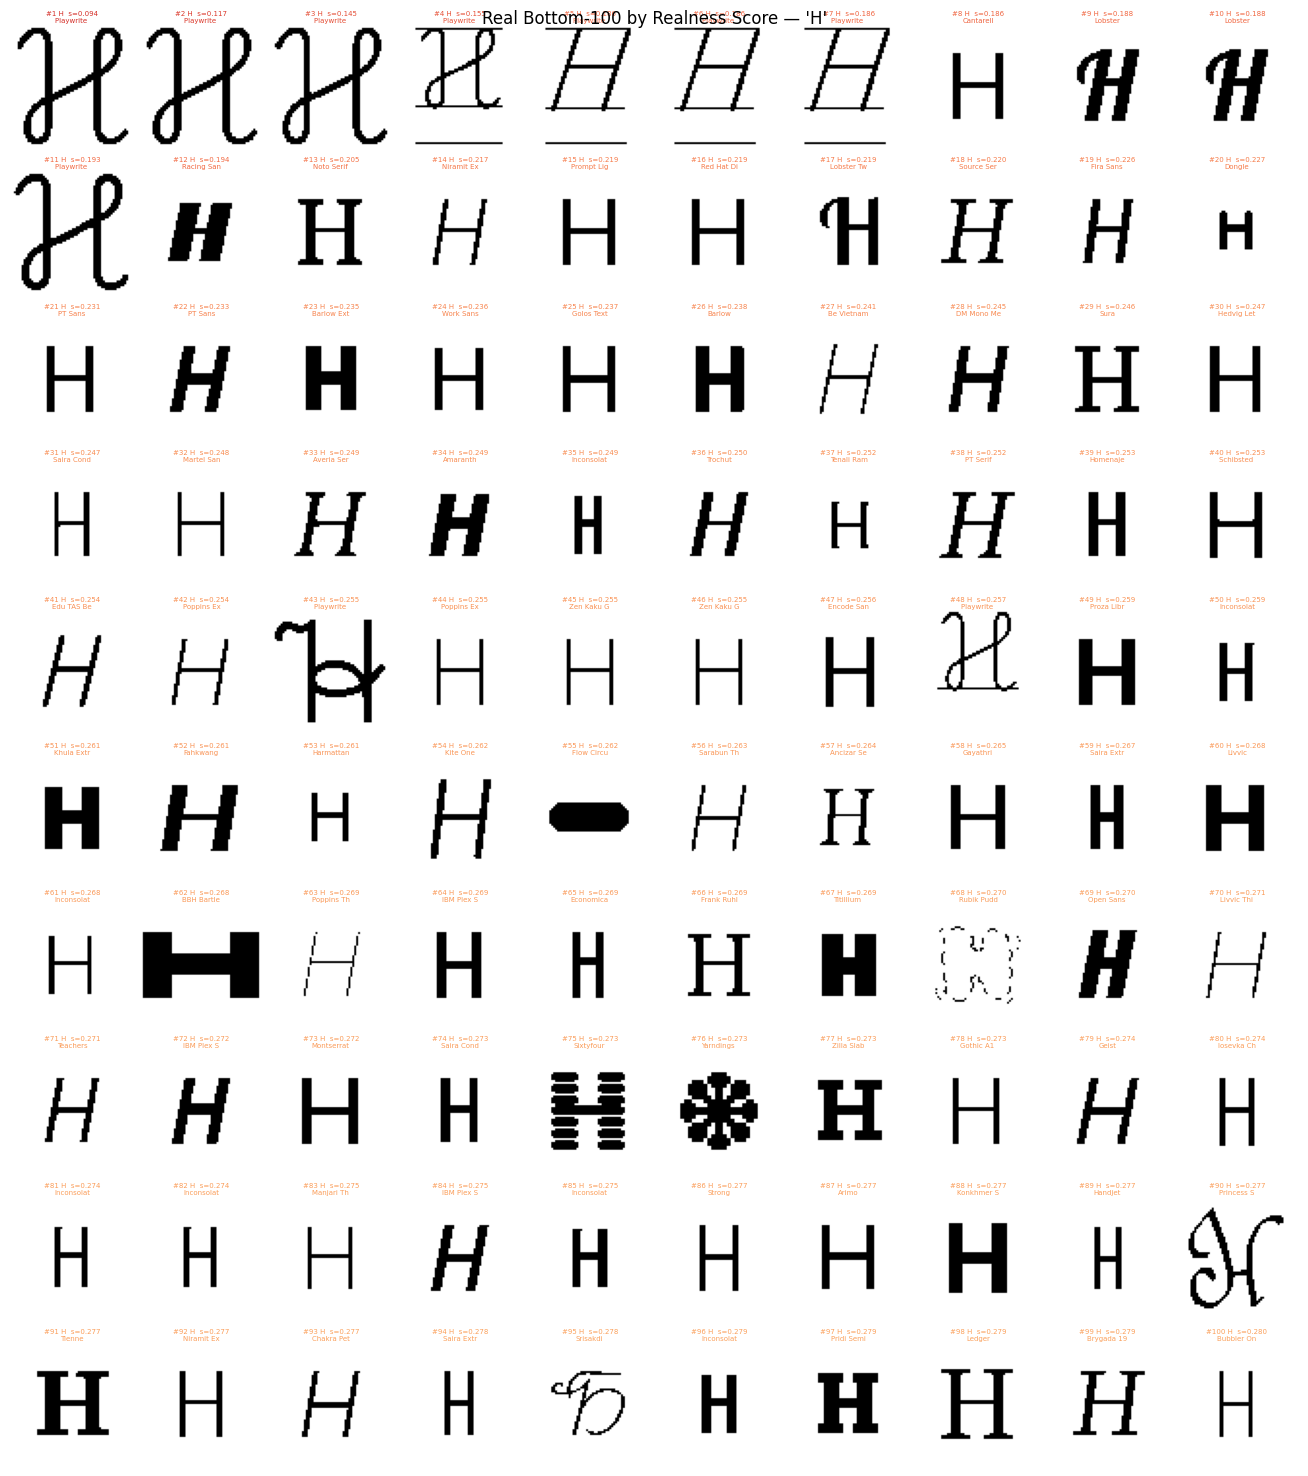

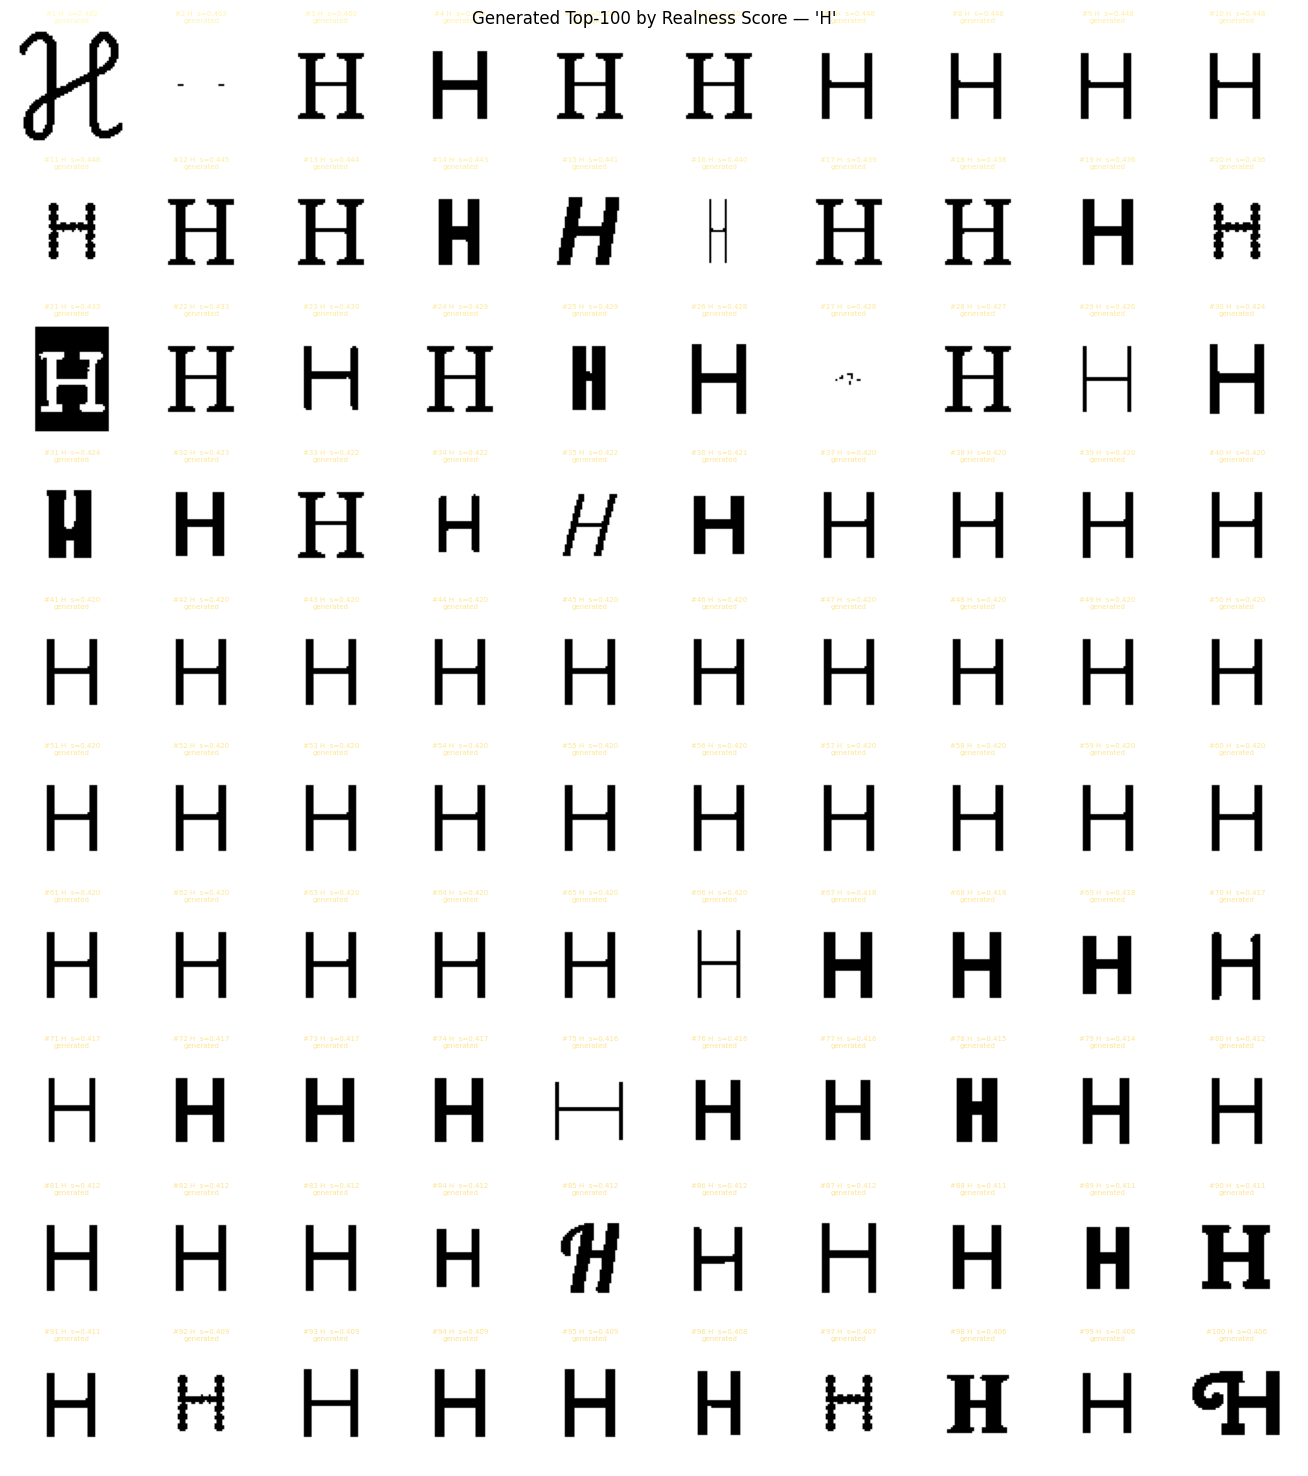

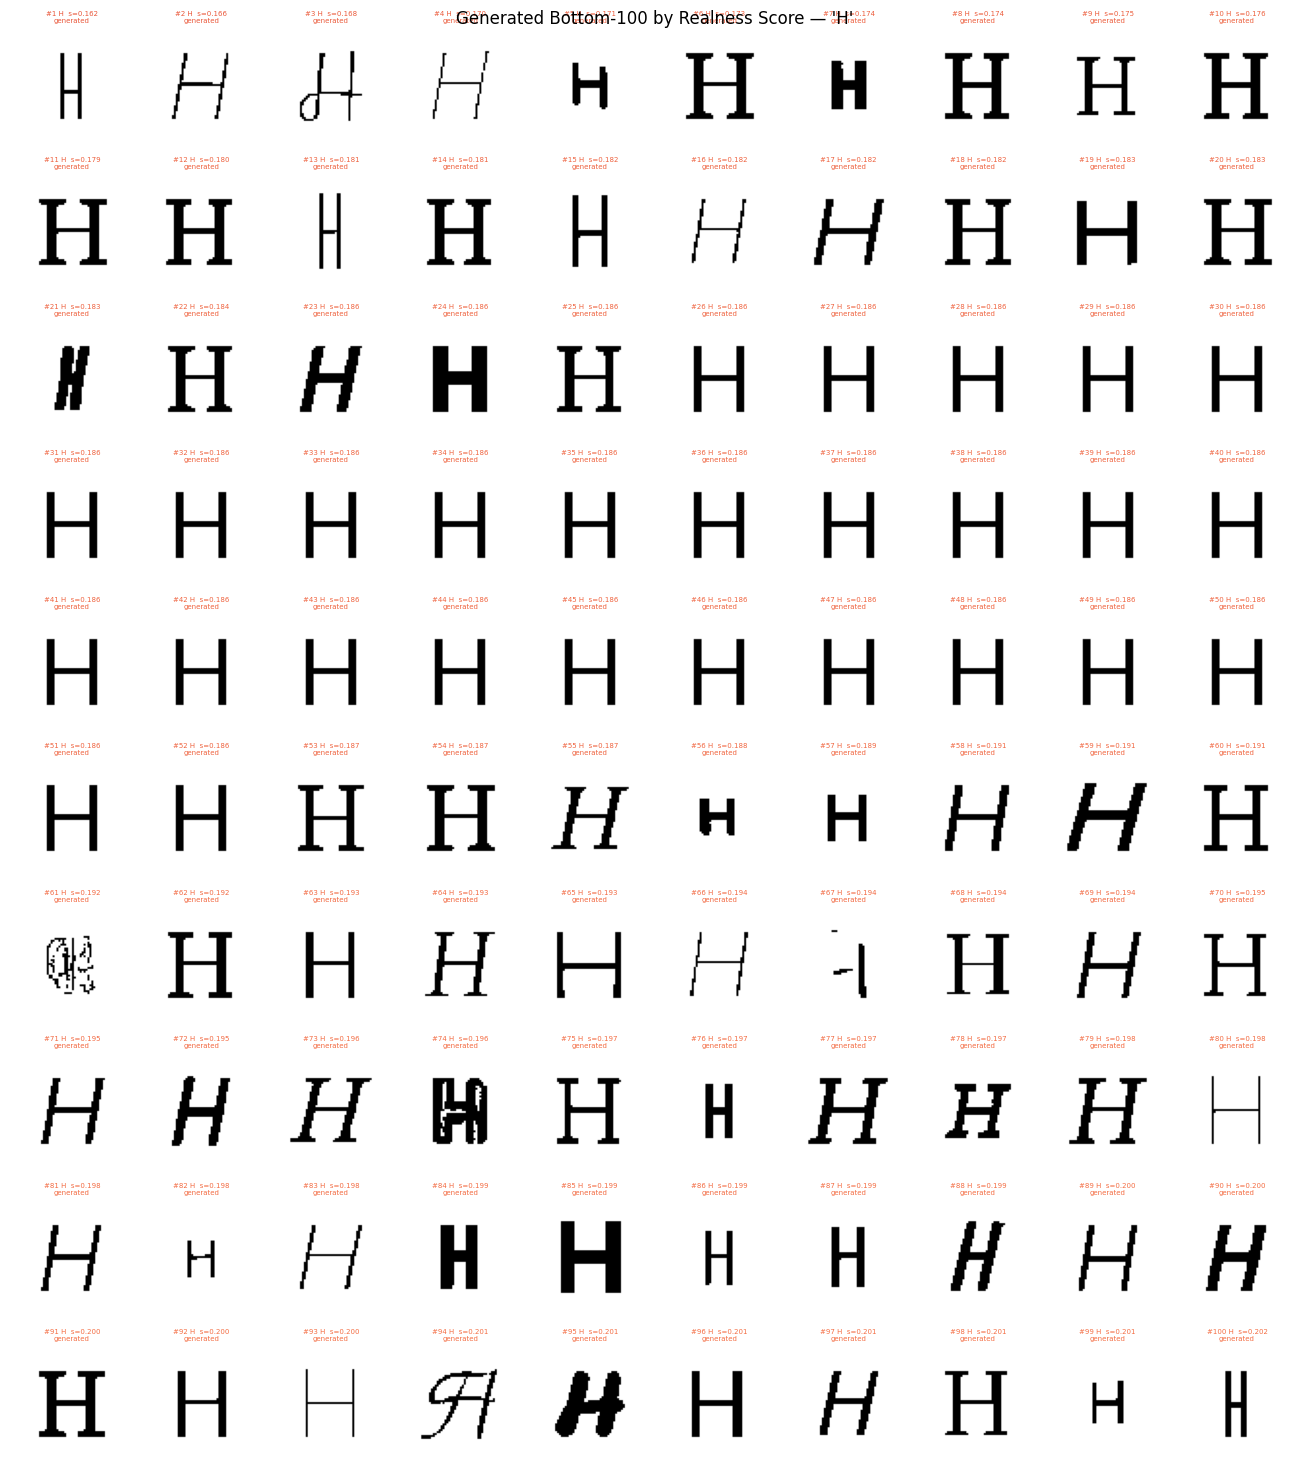

In [5]:
TOPN_N           = 100
TOPN_COLS        = 10
TOPN_FILTER_CHAR = "H"  # 空文字で全文字


def show_ranked(df: pd.DataFrame, images_dir: Path, n: int, cols: int, high: bool,
                source_label: str) -> None:
    ranked = df.nlargest(n, "realness_score") if high else df.nsmallest(n, "realness_score")
    label = "Top" if high else "Bottom"
    nrows = (len(ranked) + cols - 1) // cols
    fig, axes = plt.subplots(nrows, cols, figsize=(cols * 1.3, nrows * 1.5))
    axes = np.array(axes).reshape(-1)
    for rank, (ax, (_, row)) in enumerate(zip(axes, ranked.iterrows()), start=1):
        path = images_dir / row["file"]
        if path.exists():
            ax.imshow(_load_image(path), cmap="gray", vmin=0, vmax=1)
        else:
            ax.text(0.5, 0.5, "N/A", ha="center", va="center", fontsize=6)
        score = float(row["realness_score"])
        char  = row.get("char", "") if "char" in row.index else ""
        style = str(row.get("font_family", ""))[:10]
        ax.set_title(
            f"#{rank} {char}  s={score:.3f}\n{style}",
            fontsize=5, pad=1, color=plt.cm.RdYlGn(score),
        )
        ax.axis("off")
    for ax in axes[len(ranked):]:
        ax.axis("off")
    char_info = f" — '{TOPN_FILTER_CHAR}'" if TOPN_FILTER_CHAR else ""
    fig.suptitle(f"{source_label} {label}-{n} by Realness Score{char_info}", fontsize=12)
    fig.tight_layout(pad=0.4)
    _save_fig(fig, f"03_topbottom_{source_label.lower()}_{label.lower()}{n}")
    plt.show()


for source_label, df, images_dir in [
    ("Real",      real, REAL_DATA_DIR),
    ("Generated", gen,  GEN_DATA_DIR),
]:
    view = df.copy()
    if TOPN_FILTER_CHAR and "char" in view.columns:
        view = view[view["char"] == TOPN_FILTER_CHAR]
    view = view.dropna(subset=["realness_score"])
    show_ranked(view, images_dir, n=TOPN_N, cols=TOPN_COLS, high=True,  source_label=source_label)
    show_ranked(view, images_dir, n=TOPN_N, cols=TOPN_COLS, high=False, source_label=source_label)

## スコア範囲検索

Real 'H': 100 件  (score 0.30–0.40)


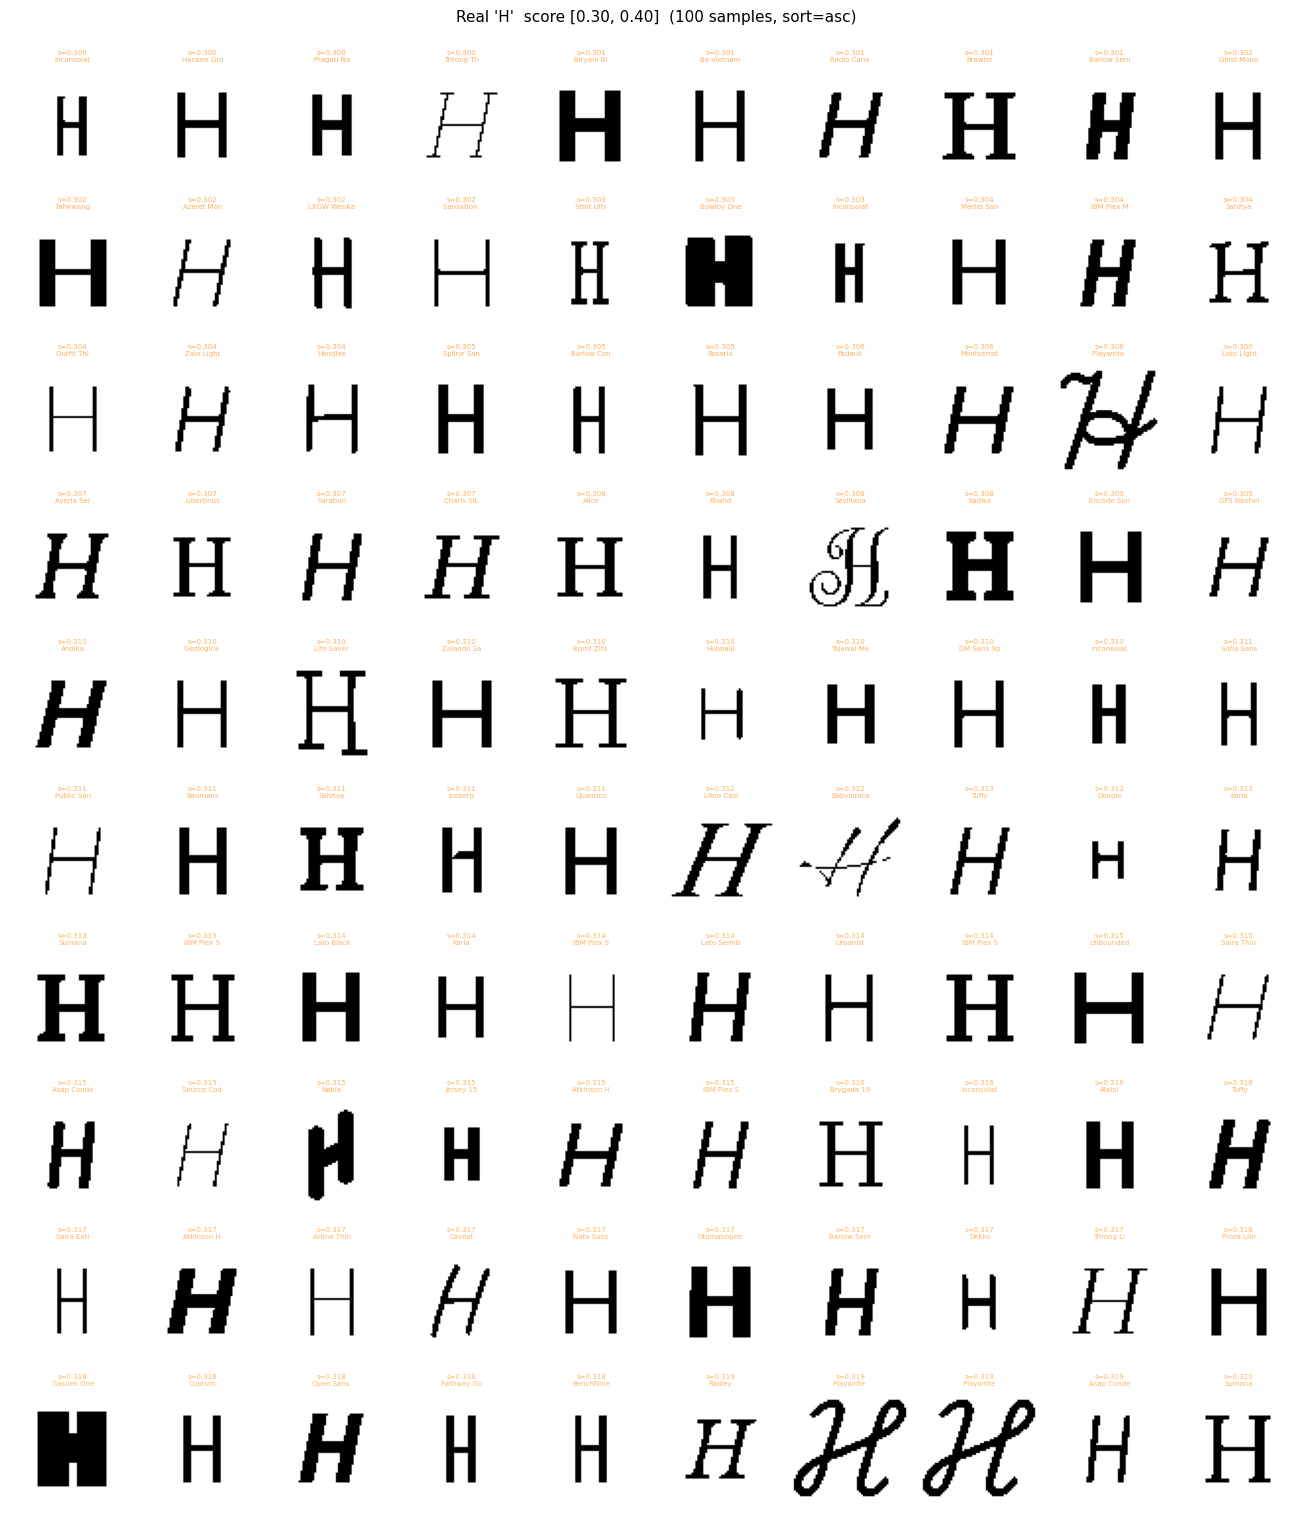

Generated 'H': 100 件  (score 0.30–0.40)


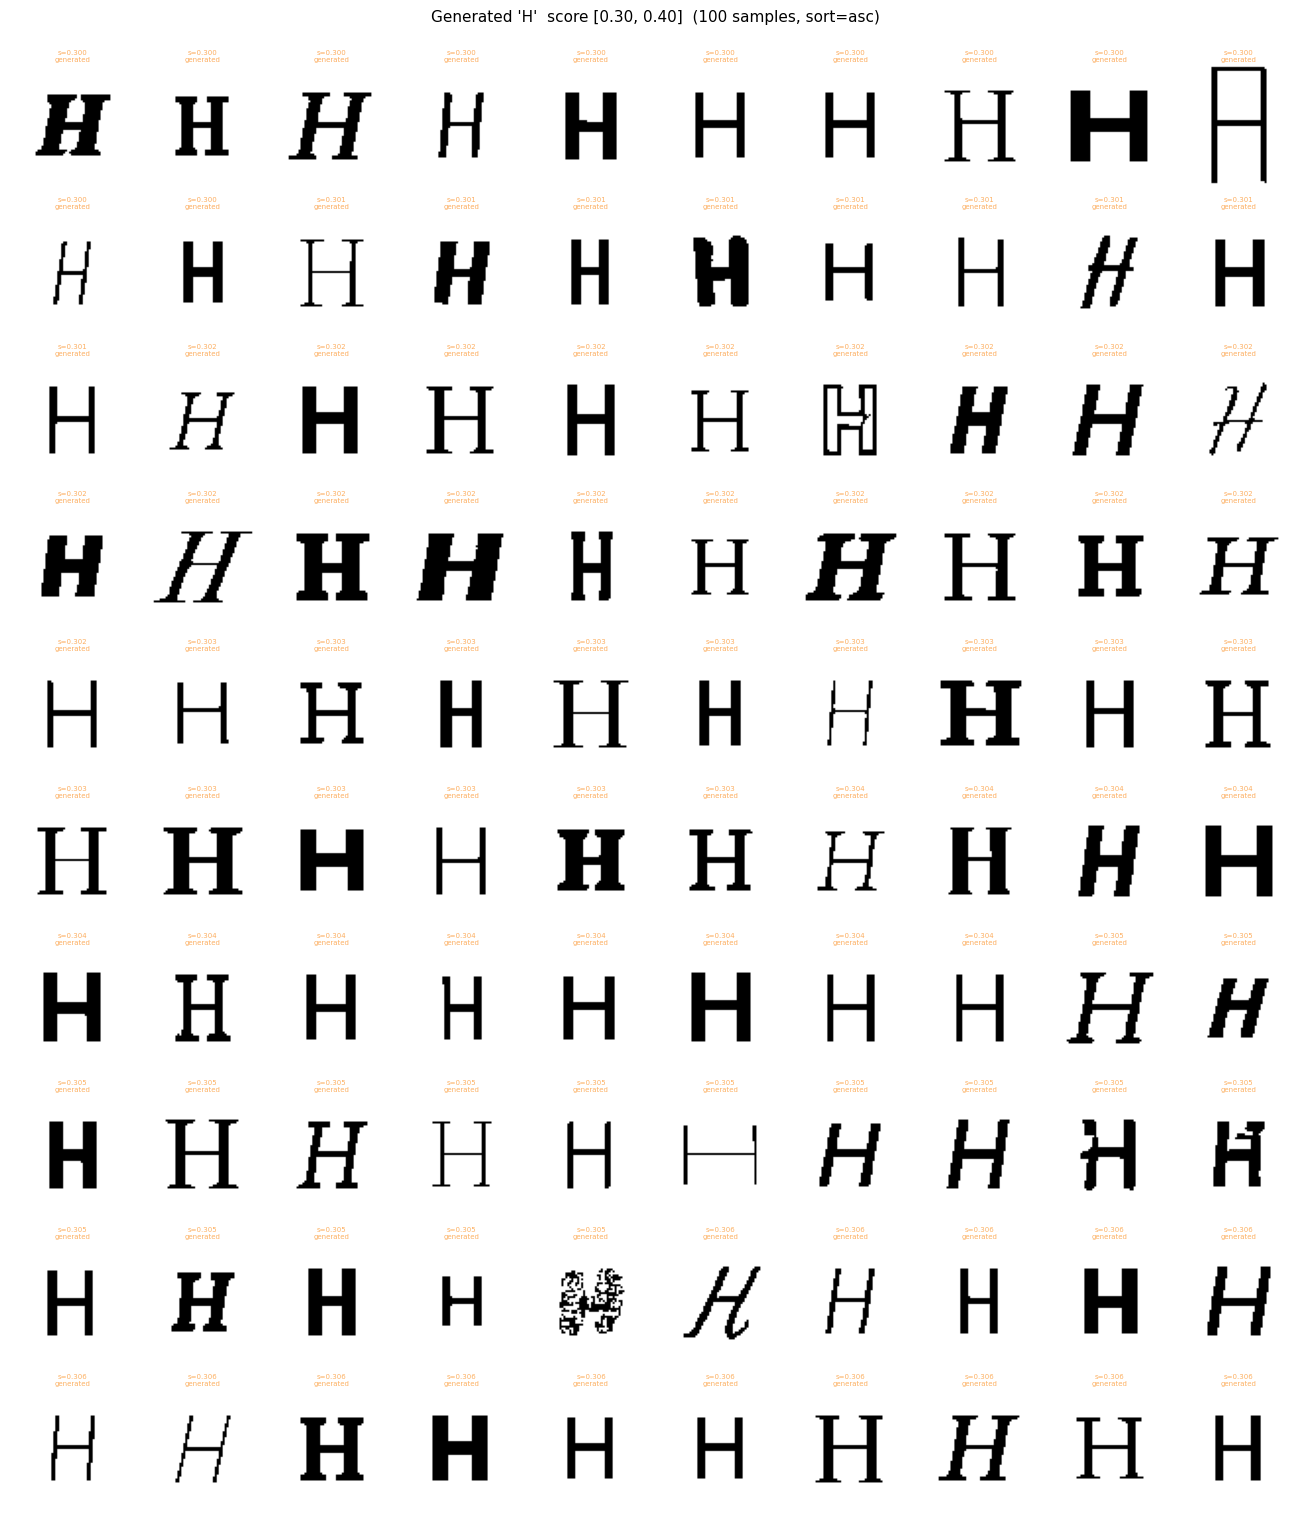

In [6]:
SEARCH_SOURCE      = "both"  # "real" | "generated" | "both"
SEARCH_SCORE_MIN   = 0.3    # スコア下限（以上）
SEARCH_SCORE_MAX   = 0.4    # スコア上限（以下）
SEARCH_FILTER_CHAR = "H"     # 空文字で全文字
SEARCH_MAX         = 100      # 最大表示枚数
SEARCH_COLS        = 10
SEARCH_SORT        = "asc"   # "asc"（低スコア順）| "desc"（高スコア順）| "random"

_source_map = {
    "real":      [(real, REAL_DATA_DIR, "Real")],
    "generated": [(gen,  GEN_DATA_DIR,  "Generated")],
    "both":      [(real, REAL_DATA_DIR, "Real"), (gen, GEN_DATA_DIR, "Generated")],
}

for df, images_dir, source_label in _source_map[SEARCH_SOURCE]:
    view = df.copy()
    if SEARCH_FILTER_CHAR and "char" in view.columns:
        view = view[view["char"] == SEARCH_FILTER_CHAR]
    view = view.dropna(subset=["realness_score"])
    view = view[(view["realness_score"] >= SEARCH_SCORE_MIN) &
                (view["realness_score"] <= SEARCH_SCORE_MAX)]

    if SEARCH_SORT == "asc":
        view = view.nsmallest(SEARCH_MAX, "realness_score")
    elif SEARCH_SORT == "desc":
        view = view.nlargest(SEARCH_MAX, "realness_score")
    else:
        view = view.sample(min(SEARCH_MAX, len(view)), random_state=0)

    char_info = f" '{SEARCH_FILTER_CHAR}'" if SEARCH_FILTER_CHAR else ""
    print(f"{source_label}{char_info}: {len(view)} 件  "
          f"(score {SEARCH_SCORE_MIN:.2f}–{SEARCH_SCORE_MAX:.2f})")

    if len(view) == 0:
        continue

    n = len(view)
    nrows = (n + SEARCH_COLS - 1) // SEARCH_COLS
    fig, axes = plt.subplots(nrows, SEARCH_COLS,
                             figsize=(SEARCH_COLS * 1.3, nrows * 1.5))
    axes = np.array(axes).reshape(-1)
    for ax, (_, row) in zip(axes, view.iterrows()):
        path = images_dir / row["file"]
        if path.exists():
            ax.imshow(_load_image(path), cmap="gray", vmin=0, vmax=1)
        else:
            ax.text(0.5, 0.5, "N/A", ha="center", va="center", fontsize=6)
        score = float(row["realness_score"])
        family = str(row.get("font_family", ""))[:10]
        ax.set_title(f"s={score:.3f}\n{family}", fontsize=5, pad=1,
                     color=plt.cm.RdYlGn(score))
        ax.axis("off")
    for ax in axes[n:]:
        ax.axis("off")
    fig.suptitle(
        f"{source_label}{char_info}  score [{SEARCH_SCORE_MIN:.2f}, {SEARCH_SCORE_MAX:.2f}]  "
        f"({n} samples, sort={SEARCH_SORT})",
        fontsize=11, y=1.01,
    )
    fig.tight_layout(pad=0.3)
    _save_fig(fig, f"04_score_range_{source_label.lower()}")
    plt.show()

## Score Statistics by Font / Font Family

In [7]:
GROUP_MIN_COUNT = 5  # Exclude font / font_family groups with fewer samples than this
TOP_TABLE_N     = 10

def _agg_scores(df: pd.DataFrame, group_cols: list[str]) -> pd.DataFrame:
    agg = df.groupby(group_cols)["realness_score"].agg(["count", "mean", "std", "min", "max"])
    return agg[agg["count"] >= GROUP_MIN_COUNT]

# Generated images only have placeholder font_family="generated" / font_style="st100_cs1.0",
# so font/font_family-level statistics are computed for real only.
real_by_family = _agg_scores(real, ["font_family"])
real_by_font    = _agg_scores(real, ["font_family", "font_style"])
real_by_style   = _agg_scores(real, ["font_style"])

_save_df(real_by_family, "08_real_by_family")
_save_df(real_by_font, "08_real_by_font")
_save_df(real_by_style, "08_real_by_style")

print(f"font_family: n={len(real_by_family)}")
print(f"font (family+style): n={len(real_by_font)}")
print(f"font_style: n={len(real_by_style)}")

print("\n--- font_family: realness_score(mean) Top/Bottom ---")
display(real_by_family.sort_values("mean", ascending=False).head(TOP_TABLE_N))
display(real_by_family.sort_values("mean", ascending=True).head(TOP_TABLE_N))

print("\n--- font (family+style): realness_score(mean) Top/Bottom ---")
display(real_by_font.sort_values("mean", ascending=False).head(TOP_TABLE_N))
display(real_by_font.sort_values("mean", ascending=True).head(TOP_TABLE_N))

print("\n--- font_family: realness_score(std) Top (families with highest score variance) ---")
display(real_by_family.sort_values("std", ascending=False).head(TOP_TABLE_N))

print("\n--- font_style: realness_score stats ---")
display(real_by_style.sort_values("mean", ascending=False))

font_family: n=1
font (family+style): n=0
font_style: n=4

--- font_family: realness_score(mean) Top/Bottom ---


,count,mean,std,min,max
font_family,,,,,
Wix Madefor Text,6,0.359109,0.028085,0.327956,0.388745


,count,mean,std,min,max
font_family,,,,,
Wix Madefor Text,6,0.359109,0.028085,0.327956,0.388745



--- font (family+style): realness_score(mean) Top/Bottom ---


,,count,mean,std,min,max
font_family,font_style,,,,,


,,count,mean,std,min,max
font_family,font_style,,,,,



--- font_family: realness_score(std) Top (families with highest score variance) ---


,count,mean,std,min,max
font_family,,,,,
Wix Madefor Text,6,0.359109,0.028085,0.327956,0.388745



--- font_style: realness_score stats ---


,count,mean,std,min,max
font_style,,,,,
Regular,1899,0.397520,0.062197,0.094183,0.636087
Bold,225,0.395797,0.052313,0.226507,0.530244
Bold Italic,82,0.382036,0.047049,0.233192,0.493295
Italic,431,0.376561,0.054091,0.216563,0.543049


/tmp/ipykernel_83030/1164688274.py:37: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1, 1].boxplot(groups, labels=styles, patch_artist=True,


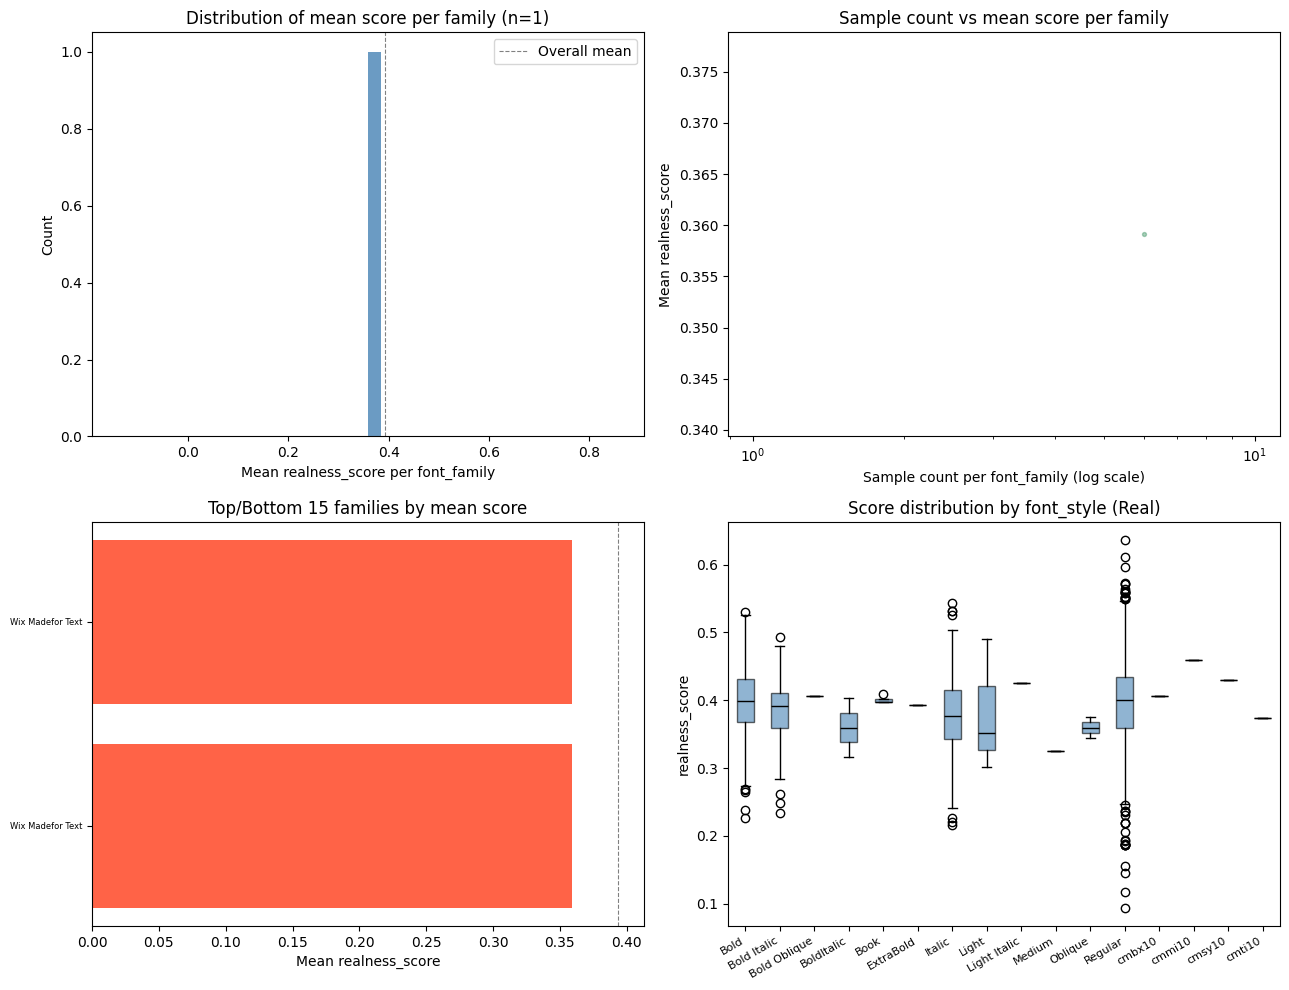

In [8]:
BAR_TOPN = 15

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# (1) Distribution of per-family mean scores
axes[0, 0].hist(real_by_family["mean"], bins=40, color="steelblue", alpha=0.8)
axes[0, 0].axvline(real["realness_score"].mean(), color="gray", linestyle="--", linewidth=0.8,
                    label="Overall mean")
axes[0, 0].set_xlabel("Mean realness_score per font_family")
axes[0, 0].set_ylabel("Count")
axes[0, 0].set_title(f"Distribution of mean score per family (n={len(real_by_family)})")
axes[0, 0].legend()

# (2) Sample count vs mean score (families with few samples have less stable means)
axes[0, 1].scatter(real_by_family["count"], real_by_family["mean"], s=8, alpha=0.4, color="seagreen")
axes[0, 1].set_xscale("log")
axes[0, 1].set_xlabel("Sample count per font_family (log scale)")
axes[0, 1].set_ylabel("Mean realness_score")
axes[0, 1].set_title("Sample count vs mean score per family")

# (3) Bar chart of Top/Bottom N families by mean score
mean_sorted = real_by_family["mean"].sort_values()
mean_bottom = mean_sorted.head(BAR_TOPN)
mean_top = mean_sorted.tail(BAR_TOPN)
mean_show = pd.concat([mean_bottom, mean_top])
colors = ["tomato" if v < real["realness_score"].mean() else "steelblue" for v in mean_show.values]
axes[1, 0].barh(range(len(mean_show)), mean_show.values, color=colors)
axes[1, 0].set_yticks(range(len(mean_show)))
axes[1, 0].set_yticklabels(mean_show.index, fontsize=6)
axes[1, 0].axvline(real["realness_score"].mean(), color="gray", linestyle="--", linewidth=0.8)
axes[1, 0].set_xlabel("Mean realness_score")
axes[1, 0].set_title(f"Top/Bottom {BAR_TOPN} families by mean score")

# (4) Score boxplot by font_style
styles = sorted(real["font_style"].unique())
groups = [real.loc[real["font_style"] == s, "realness_score"] for s in styles]
axes[1, 1].boxplot(groups, labels=styles, patch_artist=True,
                    boxprops=dict(facecolor="steelblue", alpha=0.6),
                    medianprops=dict(color="black"))
axes[1, 1].set_xticklabels(styles, rotation=30, ha="right", fontsize=8)
axes[1, 1].set_ylabel("realness_score")
axes[1, 1].set_title("Score distribution by font_style (Real)")

fig.tight_layout()
_save_fig(fig, "05_family_style_analysis")
plt.show()

### Sample Images for Fonts with Highest/Lowest Mean Scores (Real)

In [9]:
OUTLIER_TOPN = 3   # 平均スコア Top/Bottom それぞれこの件数のフォントを表示
OUTLIER_MAX_PER_FONT = 10

mean_sorted_font = real_by_font["mean"].sort_values()
outlier_fonts = pd.concat([mean_sorted_font.head(OUTLIER_TOPN), mean_sorted_font.tail(OUTLIER_TOPN)])

for (font_family, font_style), mean_score in outlier_fonts.items():
    rv = real[(real["font_family"] == font_family) & (real["font_style"] == font_style)]
    title = f"Real  {font_family} / {font_style}  (mean={mean_score:.4f}, n={len(rv)})"
    save_name = f"06_outlier_grid_{font_family}_{font_style}".replace(" ", "_")
    show_grid(rv, REAL_DATA_DIR, title=title,
              max_images=OUTLIER_MAX_PER_FONT, cols=COLS, img_size=IMG_SIZE,
              save_name=save_name)

## Image Statistics vs Realness Score

In [10]:
STAT_SAMPLE_N = -1  # Number of images to sample per source (real / generated). -1 for all samples


def _compute_image_stats(df: pd.DataFrame, images_dir: Path, n: int) -> pd.DataFrame:
    sample = df if n == -1 else df.sample(min(n, len(df)), random_state=42)
    rows = []
    for _, row in sample.iterrows():
        path = images_dir / row["file"]
        if not path.exists():
            continue
        img = _load_image(path)
        rows.append({
            "black_ratio": float((img < 0.5).mean()),
            "mean_pixel": float(img.mean()),
            "std_pixel": float(img.std()),
            "realness_score": float(row["realness_score"]),
        })
    return pd.DataFrame(rows)


real_stats = _compute_image_stats(real, REAL_DATA_DIR, STAT_SAMPLE_N)
gen_stats = _compute_image_stats(gen, GEN_DATA_DIR, STAT_SAMPLE_N)

_save_df(real_stats, "07_real_image_stats")
_save_df(gen_stats, "07_gen_image_stats")

real_stats_summary = real_stats.describe()
gen_stats_summary = gen_stats.describe()
_save_df(real_stats_summary, "07_real_image_stats_summary")
_save_df(gen_stats_summary, "07_gen_image_stats_summary")

print(f"real_stats: n={len(real_stats)}")
print(f"gen_stats: n={len(gen_stats)}")
display(real_stats_summary.round(4))
display(gen_stats_summary.round(4))

real_stats: n=2656
gen_stats: n=2650


,black_ratio,mean_pixel,std_pixel,realness_score
count,2656.0000,2656.0000,2656.0000,2656.0000
mean,0.0965,0.9035,0.2848,0.3934
std,0.0465,0.0465,0.0625,0.0601
min,0.0000,0.5605,0.0000,0.0942
25%,0.0679,0.8828,0.2515,0.3573
50%,0.0891,0.9109,0.2849,0.3951
75%,0.1172,0.9321,0.3216,0.4295
max,0.4395,1.0000,0.4963,0.6361


,black_ratio,mean_pixel,std_pixel,realness_score
count,2650.0000,2650.0000,2650.0000,2650.0000
mean,0.0956,0.9044,0.2862,0.2916
std,0.0403,0.0403,0.0540,0.0574
min,0.0015,0.6047,0.0382,0.1616
25%,0.0710,0.8843,0.2569,0.2481
50%,0.0898,0.9102,0.2860,0.2847
75%,0.1157,0.9290,0.3199,0.3321
max,0.3953,0.9985,0.4889,0.4820


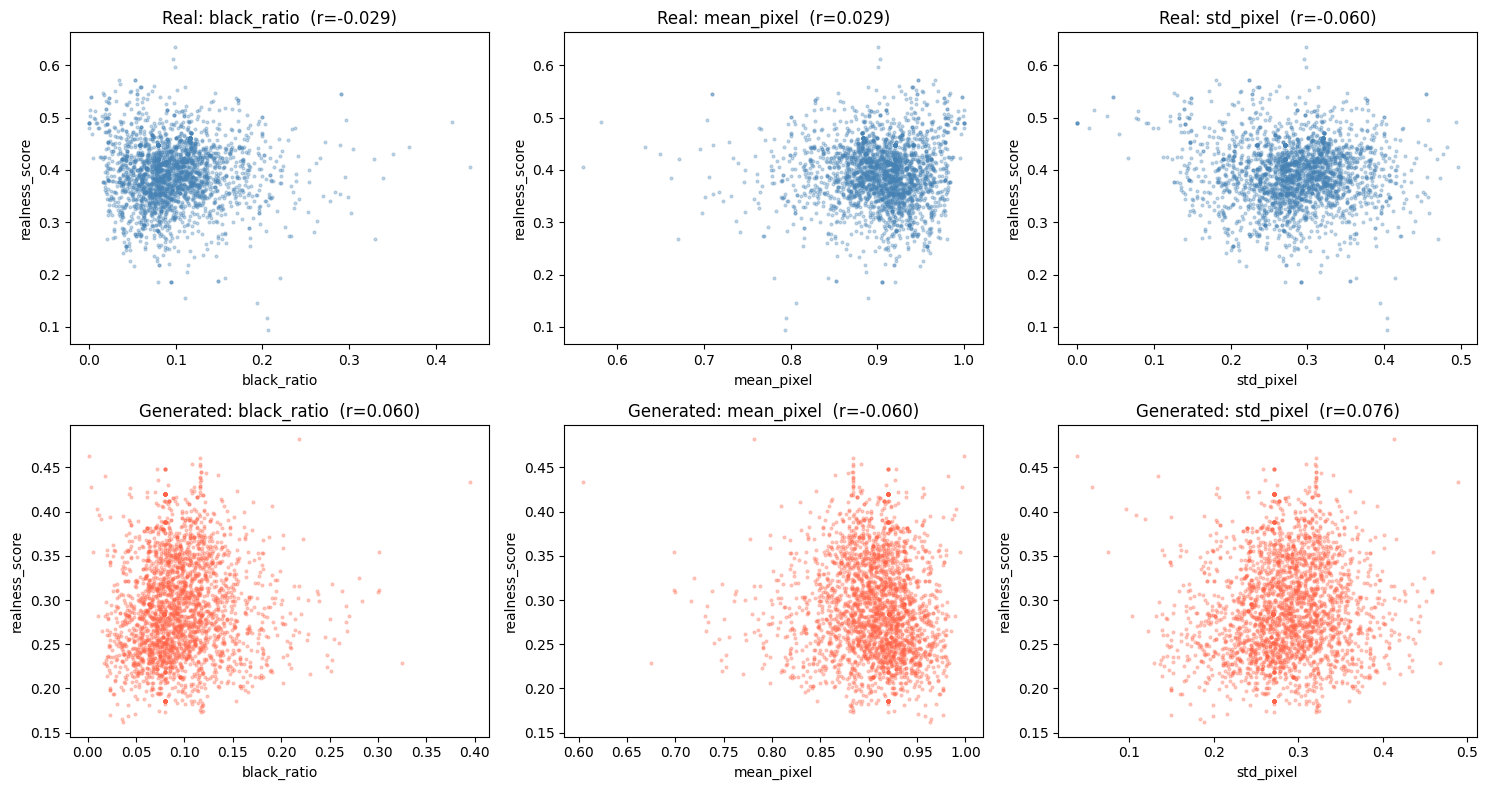

In [11]:
STAT_COLS = ["black_ratio", "mean_pixel", "std_pixel"]

fig, axes = plt.subplots(2, len(STAT_COLS), figsize=(15, 8))

for row_idx, (stats, color, label) in enumerate([
    (real_stats, "steelblue", "Real"),
    (gen_stats, "tomato", "Generated"),
]):
    for col_idx, stat_col in enumerate(STAT_COLS):
        ax = axes[row_idx, col_idx]
        x = stats[stat_col].values
        y = stats["realness_score"].values
        corr = np.corrcoef(x, y)[0, 1]
        ax.scatter(x, y, s=4, alpha=0.3, color=color)
        ax.set_xlabel(stat_col)
        ax.set_ylabel("realness_score")
        ax.set_title(f"{label}: {stat_col}  (r={corr:.3f})")

fig.tight_layout()
_save_fig(fig, "07_image_stats_vs_score")
plt.show()

## Samples Near Mean / Overlap Score

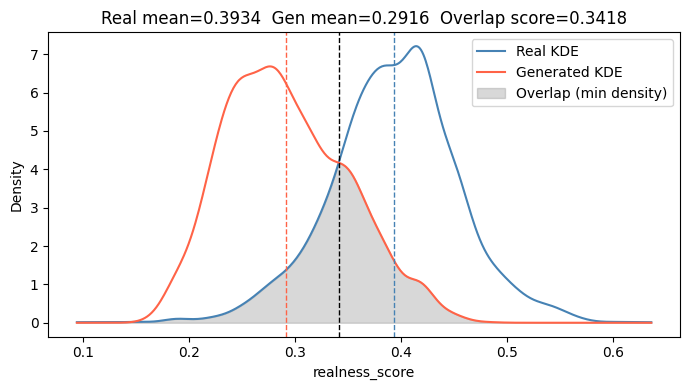

real_mean_score=0.3934  gen_mean_score=0.2916  overlap_score=0.3418


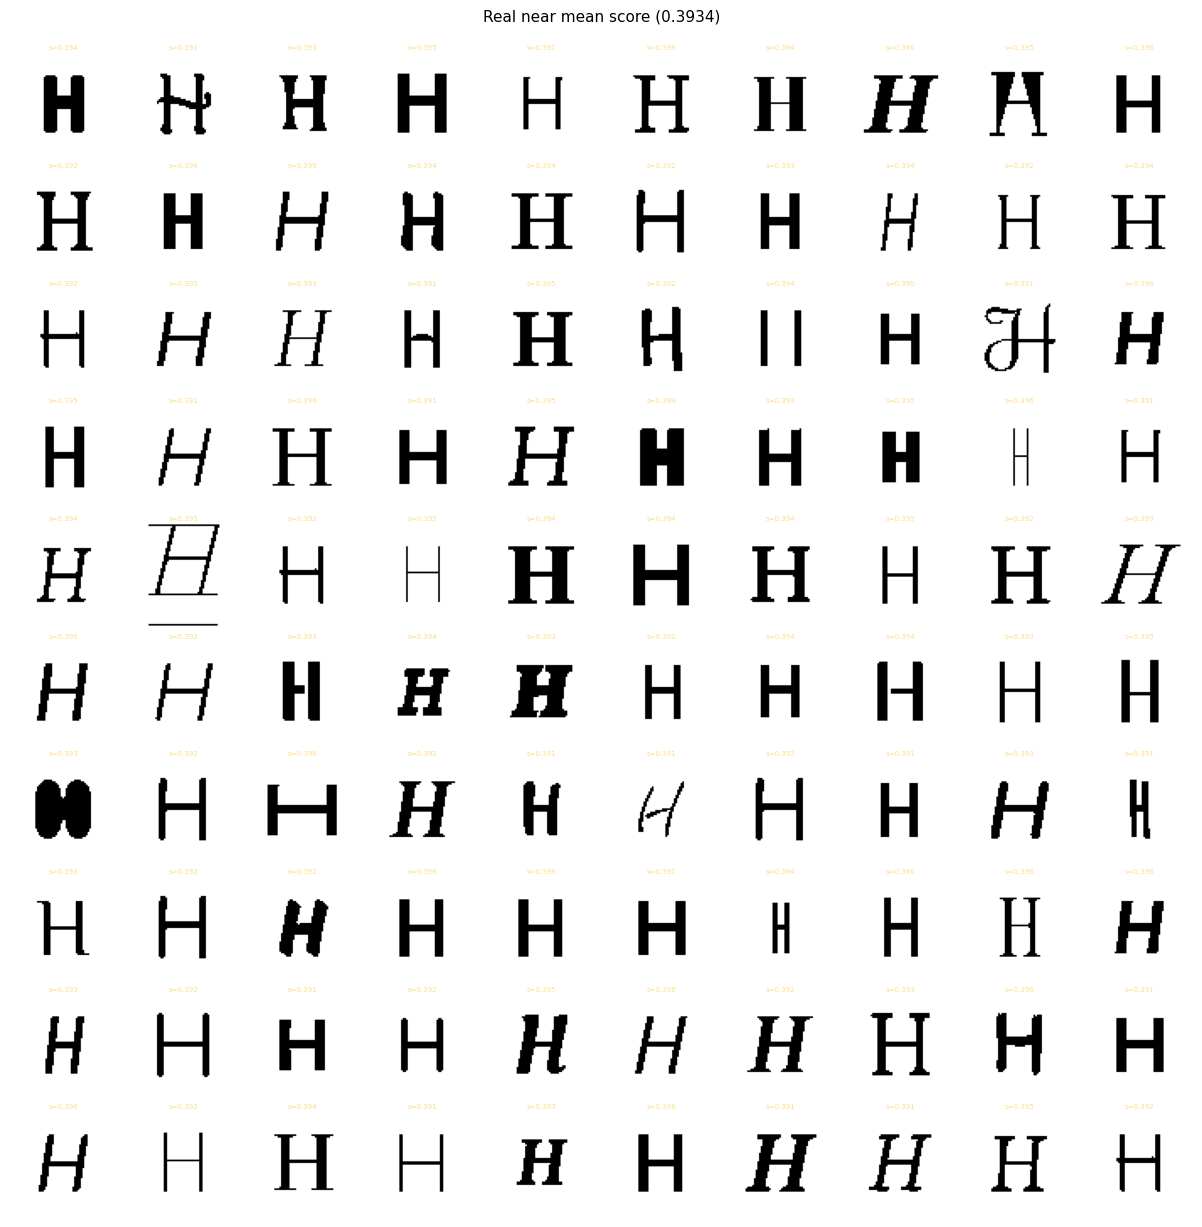

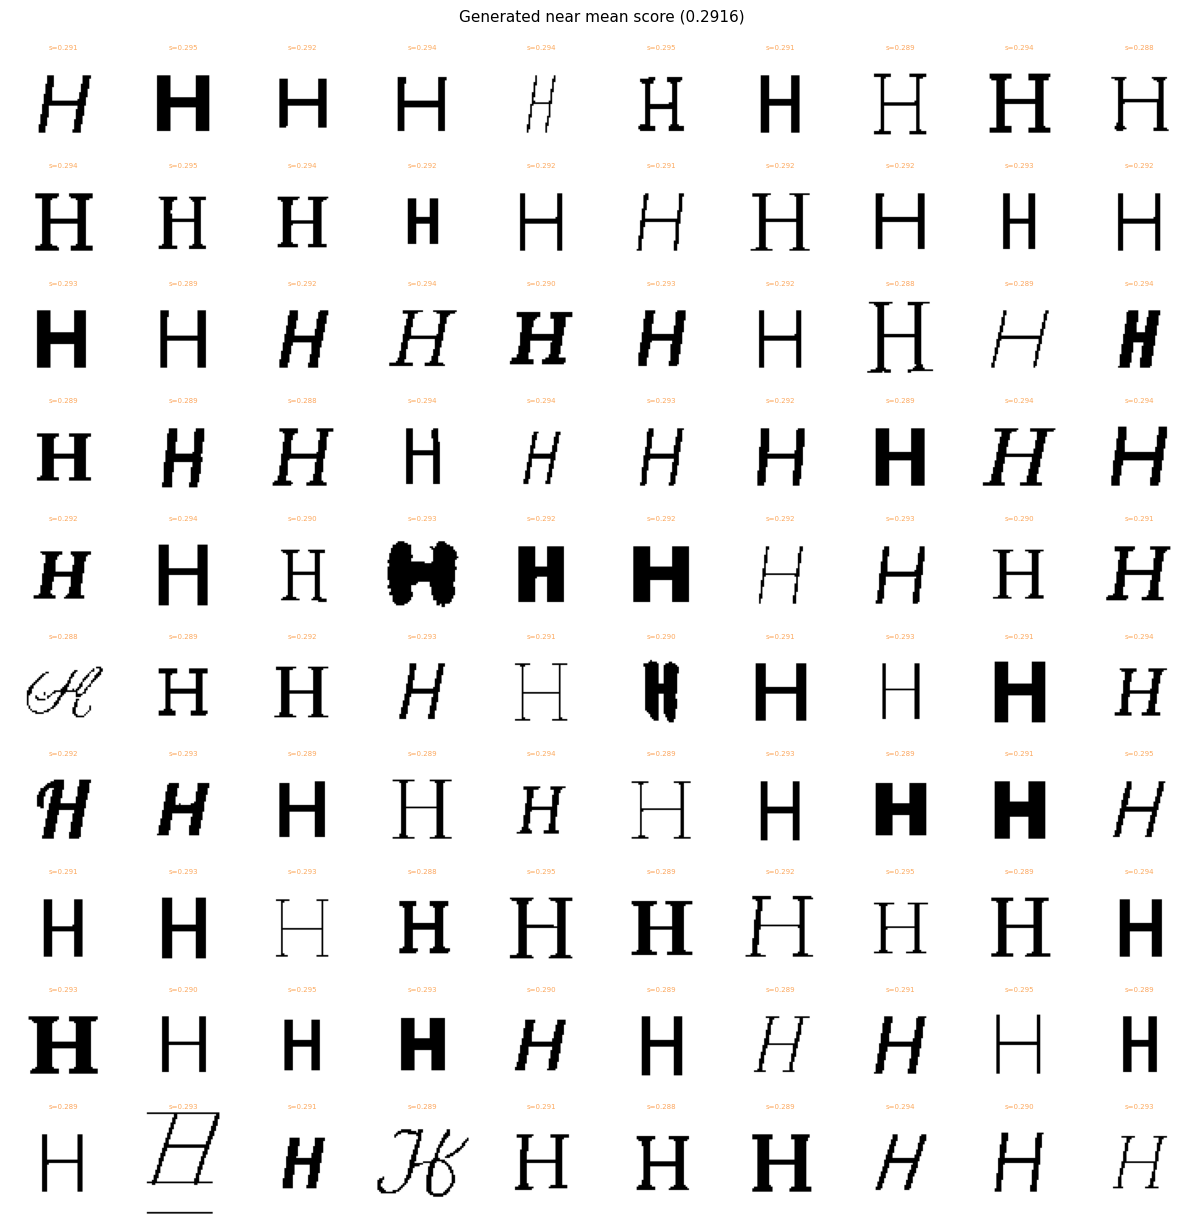

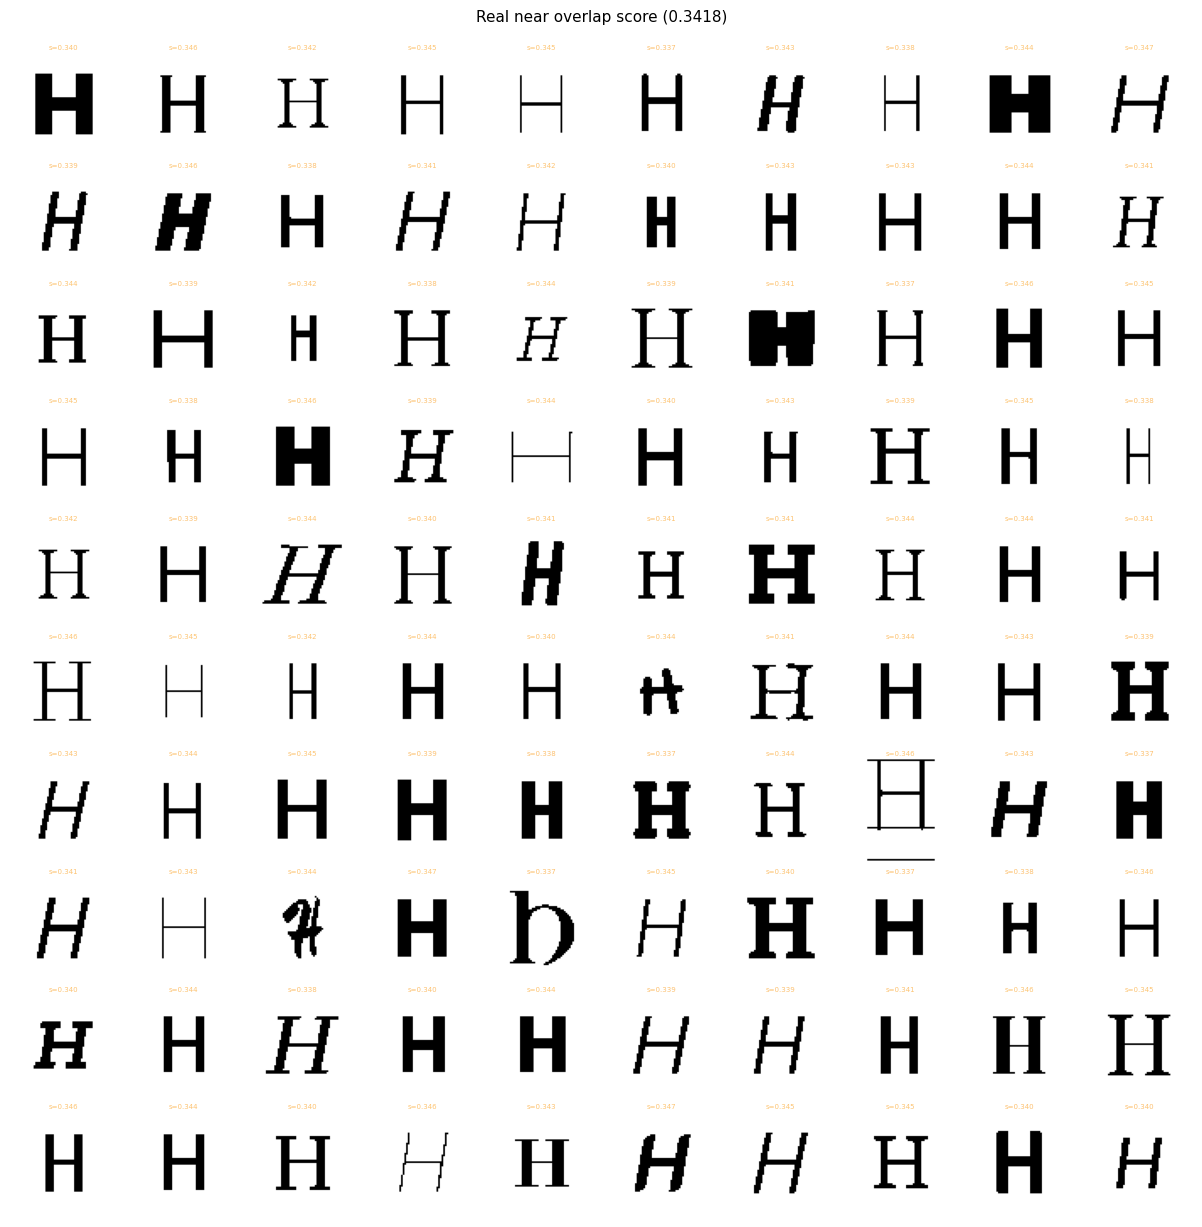

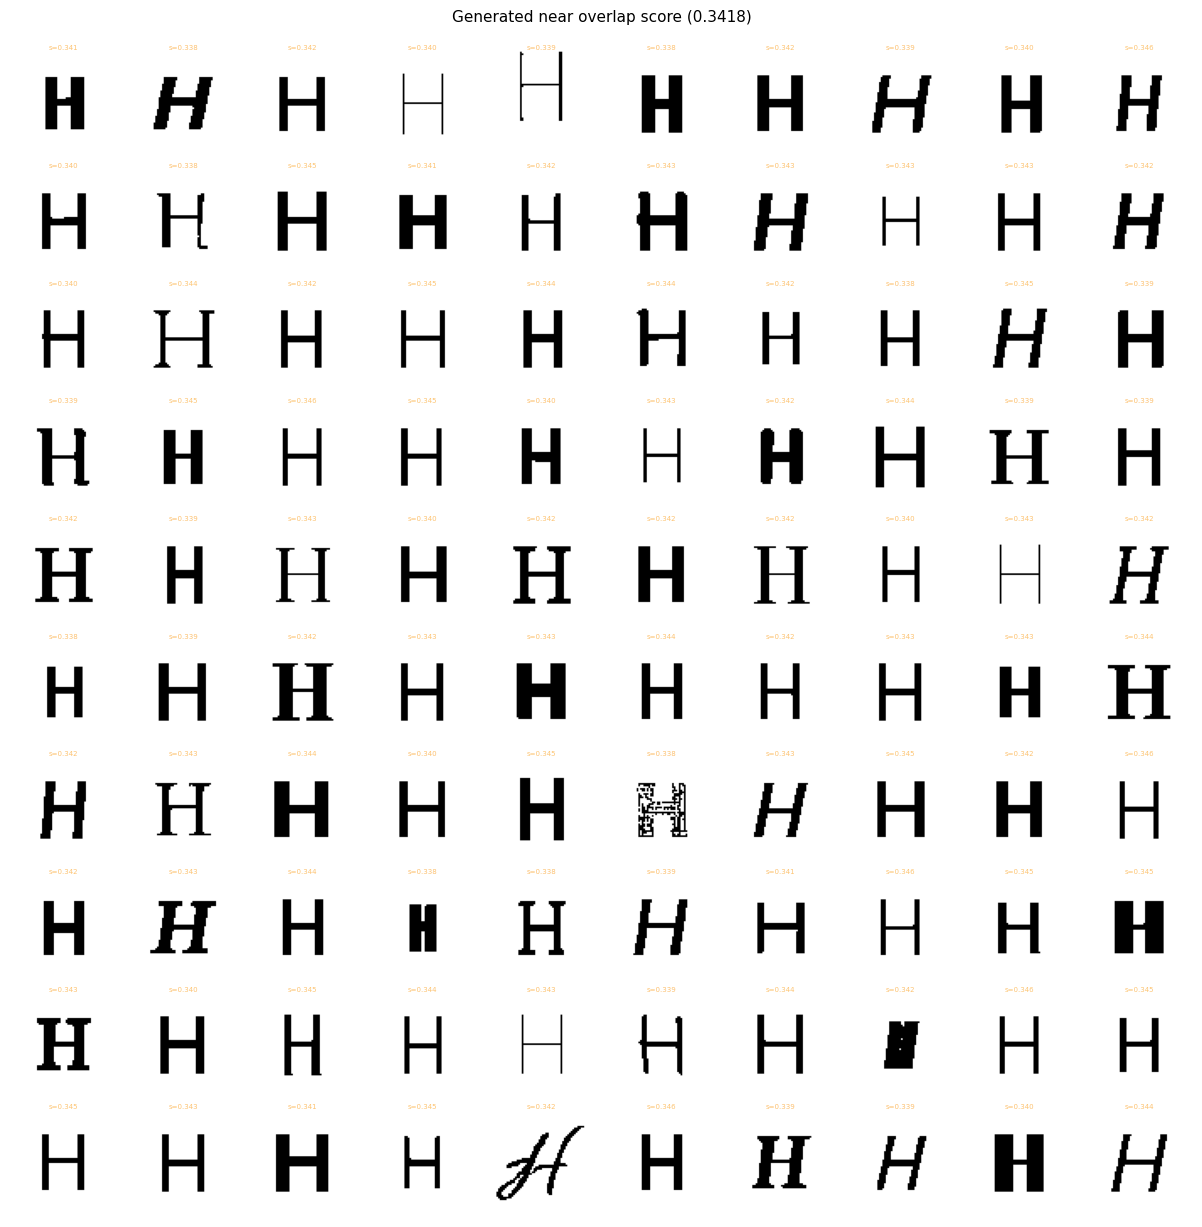

In [12]:
from scipy.stats import gaussian_kde

NEAREST_MEAN_N = 100   # Number of samples to show near mean / overlap score
NEAREST_COLS   = 10

real_scores = real["realness_score"].dropna().values
gen_scores  = gen["realness_score"].dropna().values

kde_real = gaussian_kde(real_scores)
kde_gen  = gaussian_kde(gen_scores)

grid = np.linspace(
    min(real_scores.min(), gen_scores.min()),
    max(real_scores.max(), gen_scores.max()),
    500,
)
overlap_density = np.minimum(kde_real(grid), kde_gen(grid))
overlap_score = float(grid[np.argmax(overlap_density)])

real_mean_score = float(real_scores.mean())
gen_mean_score  = float(gen_scores.mean())

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(grid, kde_real(grid), color="steelblue", label="Real KDE")
ax.plot(grid, kde_gen(grid), color="tomato", label="Generated KDE")
ax.fill_between(grid, 0, overlap_density, color="gray", alpha=0.3, label="Overlap (min density)")
for x, color, _label in [
    (real_mean_score, "steelblue", "Real mean"),
    (gen_mean_score, "tomato", "Generated mean"),
    (overlap_score, "black", "Overlap score"),
]:
    ax.axvline(x, color=color, linestyle="--", linewidth=1)
ax.set_xlabel("realness_score")
ax.set_ylabel("Density")
ax.set_title(
    f"Real mean={real_mean_score:.4f}  Gen mean={gen_mean_score:.4f}  "
    f"Overlap score={overlap_score:.4f}"
)
ax.legend()
fig.tight_layout()
_save_fig(fig, "09_score_kde_overlap")
plt.show()

print(f"real_mean_score={real_mean_score:.4f}  gen_mean_score={gen_mean_score:.4f}  "
      f"overlap_score={overlap_score:.4f}")


def _nearest_to(df: pd.DataFrame, target: float, n: int) -> pd.DataFrame:
    view = df.dropna(subset=["realness_score"]).copy()
    return view.iloc[(view["realness_score"] - target).abs().argsort()[:n]]


show_grid(
    _nearest_to(real, real_mean_score, NEAREST_MEAN_N), REAL_DATA_DIR,
    title=f"Real near mean score ({real_mean_score:.4f})",
    max_images=NEAREST_MEAN_N, cols=NEAREST_COLS, img_size=IMG_SIZE,
    save_name="09_near_real_mean",
)
show_grid(
    _nearest_to(gen, gen_mean_score, NEAREST_MEAN_N), GEN_DATA_DIR,
    title=f"Generated near mean score ({gen_mean_score:.4f})",
    max_images=NEAREST_MEAN_N, cols=NEAREST_COLS, img_size=IMG_SIZE,
    save_name="09_near_gen_mean",
)
show_grid(
    _nearest_to(real, overlap_score, NEAREST_MEAN_N), REAL_DATA_DIR,
    title=f"Real near overlap score ({overlap_score:.4f})",
    max_images=NEAREST_MEAN_N, cols=NEAREST_COLS, img_size=IMG_SIZE,
    save_name="09_near_overlap_real",
)
show_grid(
    _nearest_to(gen, overlap_score, NEAREST_MEAN_N), GEN_DATA_DIR,
    title=f"Generated near overlap score ({overlap_score:.4f})",
    max_images=NEAREST_MEAN_N, cols=NEAREST_COLS, img_size=IMG_SIZE,
    save_name="09_near_overlap_gen",
)

## 再現用パラメータの保存

In [13]:
run_config = {
    # --- パス設定（セル 72172d32）---
    "REAL_DATA_DIR": REAL_DATA_DIR,
    "REAL_PARQUET": REAL_PARQUET,
    "REAL_SPLIT_FILE": REAL_SPLIT_FILE,
    "GEN_DATA_DIR": GEN_DATA_DIR,
    "GEN_PARQUET": GEN_PARQUET,
    "GEN_SPLIT_FILE": GEN_SPLIT_FILE,
    # --- 表示設定（セル 72172d32）---
    "SPLIT": SPLIT,
    "FILTER_CHARS": FILTER_CHARS,
    "FILTER_FAMILY": FILTER_FAMILY,
    "MAX_PER_CHAR": MAX_PER_CHAR,
    "COLS": COLS,
    "IMG_SIZE": IMG_SIZE,
    "BINARIZE": BINARIZE,
    "BINARIZE_THRESHOLD": BINARIZE_THRESHOLD,
    # --- セクション別パラメータ ---
    "DISPLAY_MODE": DISPLAY_MODE,
    "TOPN_N": TOPN_N,
    "TOPN_COLS": TOPN_COLS,
    "TOPN_FILTER_CHAR": TOPN_FILTER_CHAR,
    "SEARCH_SOURCE": SEARCH_SOURCE,
    "SEARCH_SCORE_MIN": SEARCH_SCORE_MIN,
    "SEARCH_SCORE_MAX": SEARCH_SCORE_MAX,
    "SEARCH_FILTER_CHAR": SEARCH_FILTER_CHAR,
    "SEARCH_MAX": SEARCH_MAX,
    "SEARCH_COLS": SEARCH_COLS,
    "SEARCH_SORT": SEARCH_SORT,
    "GROUP_MIN_COUNT": GROUP_MIN_COUNT,
    "TOP_TABLE_N": TOP_TABLE_N,
    "BAR_TOPN": BAR_TOPN,
    "OUTLIER_TOPN": OUTLIER_TOPN,
    "OUTLIER_MAX_PER_FONT": OUTLIER_MAX_PER_FONT,
    "STAT_SAMPLE_N": STAT_SAMPLE_N,
    "STAT_COLS": STAT_COLS,
    "NEAREST_MEAN_N": NEAREST_MEAN_N,
    "NEAREST_COLS": NEAREST_COLS,
    # --- 算出値（セル d7127724）---
    "real_mean_score": real_mean_score,
    "gen_mean_score": gen_mean_score,
    "overlap_score": overlap_score,
}
_save_config(run_config, "config")
print(f"Saved run config to {OUTPUT_DIR / 'config.yaml'}")

Saved run config to models/2026-06-15-11-30_scorer_H/checkpoints/step003150-auroc0.6284/viewer/config.yaml
